In [1]:
import os, sys
from PIL import Image
from tqdm import tqdm
import yaml


# Add the project root directory to sys.path
project_root = os.path.abspath('../..')  # Adjust this path if needed
sys.path.append(project_root)

from utils import get_images_from_list, create_file_names_list, file_name_from_file_path
from utils import mask_on_image, dilate_mask, plot_grid

from inpainting_iopaint_lama_flux import inpaint_instance_iopaint_lama_flux
from inpainting_flux import setup_diffusion_model_flux

2025-01-24 12:47:38.682826: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1737722858.699606   10037 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1737722858.704240   10037 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2025-01-24 12:47:38.724633: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
/usr/local/lib/python3.10/site-packages/xformers/ops/fmha/flash.py:211: FutureWarning: `torch.library.impl_abstract` was rena

The token has not been saved to the git credentials helper. Pass `add_to_git_credential=True` in this function directly or `--add-to-git-credential` if using via `huggingface-cli` if you want to set the git credential as well.
Token is valid (permission: fineGrained).
Your token has been saved to /common-repos/LMs/token
Login successful


## Datasets
### Load ISIC 2019 dataset

In [2]:
# Load the YAML file into a dictionary
dataset_yaml_file = "/workspace/home/data/datasets.yaml"
with open(dataset_yaml_file, "r") as file:
    datasets = yaml.safe_load(file)


# get dataset
dataset_key = "ISIC2019"
dataset = datasets[dataset_key]

## Setup images, prompt, dilation settings, and models

In [3]:
def convert_img_id(img_id, datset_name):
    if datset_name == "ISIC2019":
        # 55292 -> ISIC_0055292.jpg
        # 10 -> ISIC_0000010.jpg
        return f"ISIC_{str(img_id).zfill(7)}.jpg"
    elif datset_name == "Pascal_VOC07":
        # 27 -> 000027.jpg
        # 10 -> 000010.jpg
        return f"{str(img_id).zfill(6)}.jpg"
mask_ids = [604, 712, 592, 610, 932, 9040, 600]

In [ ]:
pipe, generator = setup_diffusion_model_flux(device = 0)
# unexpected keyword argument 'strict' ->  pip install accelerate -U

In [6]:
n = 20
segmentation_id = 'gt'
images_path = dataset["raw_path"]
#segmentation_masks_path = dataset['gt_seg_path']
segmentation_masks_path = f"/workspace/home/pipeline_outputs/{dataset_key}/{segmentation_id}/seg"
mask_names = create_file_names_list(segmentation_masks_path, ignore_copy=True)[:n]
#mask_names = [convert_img_id(mask_id, dataset_key) for mask_id in mask_ids]
print(mask_names)
images = get_images_from_list(mask_names, images_path, sub_dir=True)
segmentation_masks = get_images_from_list(mask_names, segmentation_masks_path, sub_dir=True)
prompt = "part of skin in homogenous skin color"
# "remove the colorful patch and replace with skin tissue"

# For dilating the mask
kernel_size = 5
iterations = 4


['ISIC_0000557.jpg', 'ISIC_0000558.jpg', 'ISIC_0000559.jpg', 'ISIC_0000560.jpg', 'ISIC_0000561.jpg', 'ISIC_0000562.jpg', 'ISIC_0000563.jpg', 'ISIC_0000564.jpg', 'ISIC_0000565.jpg', 'ISIC_0000566.jpg', 'ISIC_0000567.jpg', 'ISIC_0000568.jpg', 'ISIC_0000569.jpg', 'ISIC_0000570.jpg', 'ISIC_0000571.jpg', 'ISIC_0000572.jpg', 'ISIC_0000573.jpg', 'ISIC_0000574.jpg', 'ISIC_0000575.jpg', 'ISIC_0000576.jpg']


Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

OutOfMemoryError: CUDA out of memory. Tried to allocate 72.00 MiB. GPU 0 has a total capacity of 47.54 GiB of which 52.00 MiB is free. Process 1628106 has 370.00 MiB memory in use. Process 1437861 has 370.00 MiB memory in use. Process 3642275 has 46.75 GiB memory in use. Of the allocated memory 46.40 GiB is allocated by PyTorch, and 30.33 MiB is reserved by PyTorch but unallocated. If reserved but unallocated memory is large try setting PYTORCH_CUDA_ALLOC_CONF=expandable_segments:True to avoid fragmentation.  See documentation for Memory Management  (https://pytorch.org/docs/stable/notes/cuda.html#environment-variables)

## Run model on segmentations and visualize the inpainting

  0%|          | 0/20 [00:00<?, ?it/s]2025-01-24 12:48:50.664 | INFO     | iopaint.runtime:setup_model_dir:80 - Model directory: /root/.cache
E0000 00:00:1737722934.514044   11260 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1737722934.518342   11260 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
/usr/local/lib/python3.10/site-packages/xformers/ops/fmha/flash.py:211: FutureWarning: `torch.library.impl_abstract` was renamed to `torch.library.register_fake`. Please use that instead; we will remove `torch.library.impl_abstract` in a future version of PyTorch.
  @torch.library.impl_abstract("xformers_flash::flash_fwd")
/usr/local/lib/python3.10/site-packages/xformers/ops/fmha/flash.py:344: FutureWarning: `torch.library.impl_abstract` was renamed to `torch.library.register_fake`. Please use that i

⠋ Batch processing... ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━   0% 0/1 0:00:00

2025-01-24 12:49:00.504 | INFO     | iopaint.model.base:__call__:97 - Run crop strategy


  Batch processing... ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 100% 1/1 0:00:2000:20


  0%|          | 0/50 [00:00<?, ?it/s]

Image: ISIC_0000557.jpg


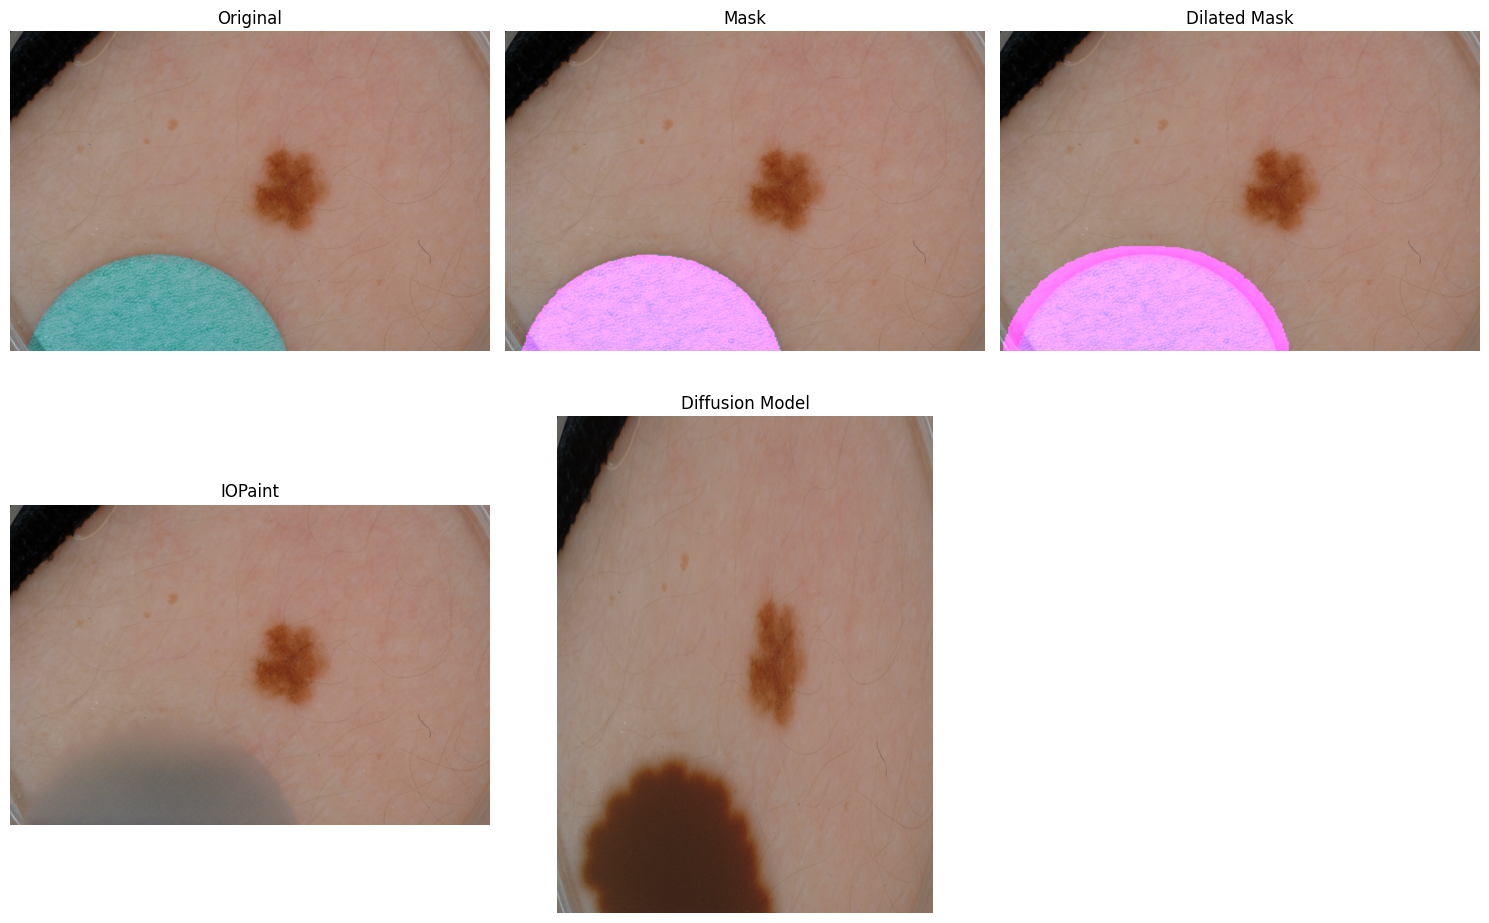

  5%|▌         | 1/20 [02:37<49:48, 157.29s/it]2025-01-24 12:51:28.571 | INFO     | iopaint.runtime:setup_model_dir:80 - Model directory: /root/.cache
E0000 00:00:1737723093.294090   11929 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1737723093.298660   11929 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
/usr/local/lib/python3.10/site-packages/xformers/ops/fmha/flash.py:211: FutureWarning: `torch.library.impl_abstract` was renamed to `torch.library.register_fake`. Please use that instead; we will remove `torch.library.impl_abstract` in a future version of PyTorch.
  @torch.library.impl_abstract("xformers_flash::flash_fwd")
/usr/local/lib/python3.10/site-packages/xformers/ops/fmha/flash.py:344: FutureWarning: `torch.library.impl_abstract` was renamed to `torch.library.register_fake`. Please u

⠙ Batch processing... ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━   0% 0/1 0:00:00

2025-01-24 12:51:37.794 | INFO     | iopaint.model.base:__call__:97 - Run crop strategy


  Batch processing... ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 100% 1/1 0:00:0300:03


  0%|          | 0/50 [00:00<?, ?it/s]

Image: ISIC_0000558.jpg


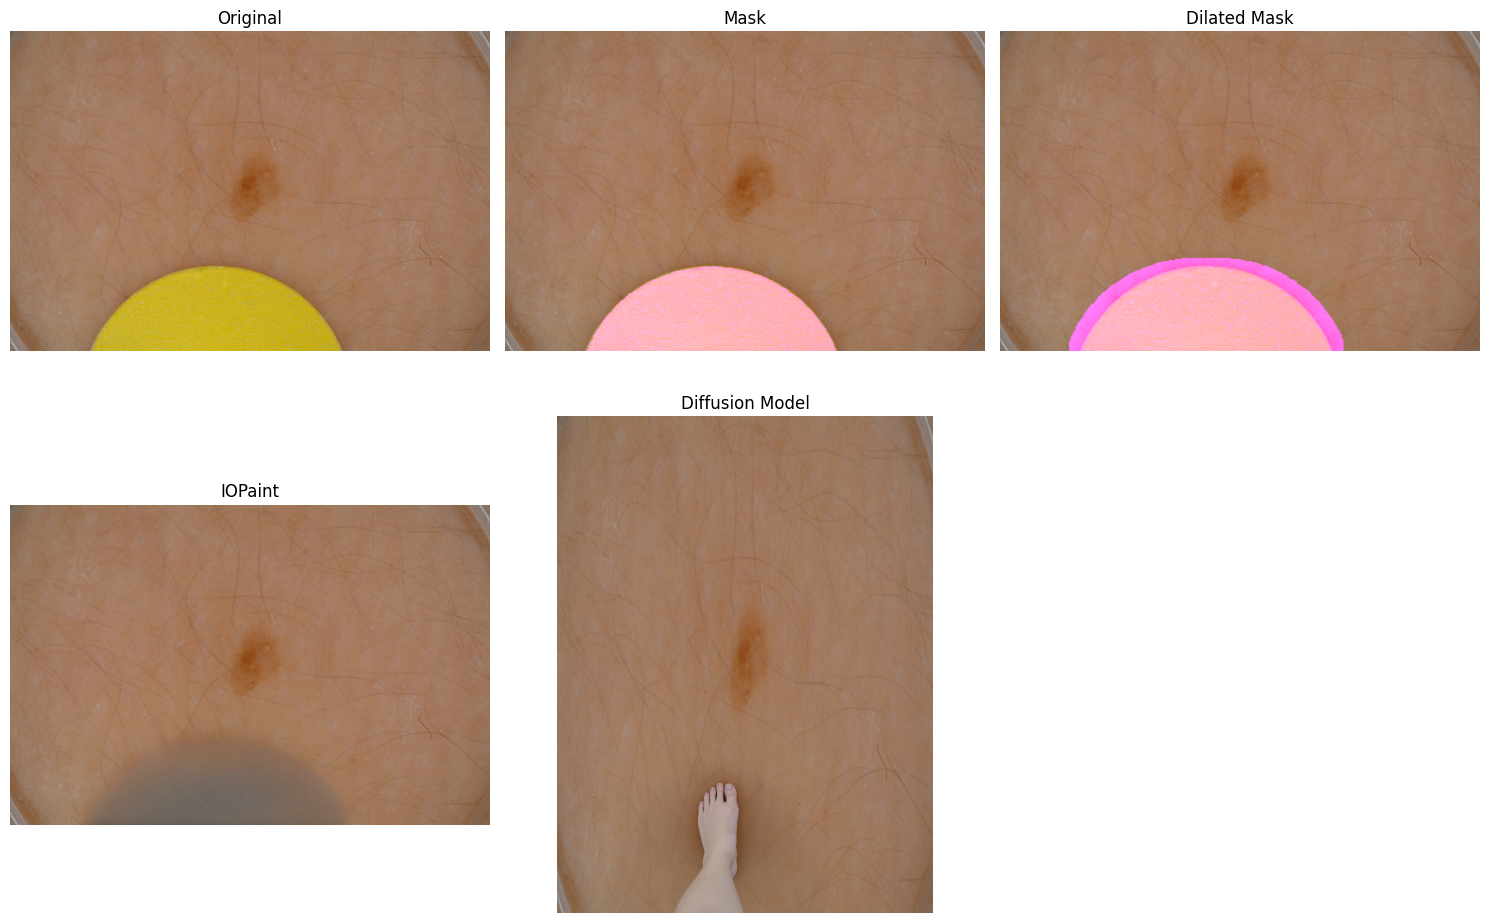

 10%|█         | 2/20 [04:34<40:05, 133.63s/it]2025-01-24 12:53:25.715 | INFO     | iopaint.runtime:setup_model_dir:80 - Model directory: /root/.cache
E0000 00:00:1737723210.220913   12332 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1737723210.225451   12332 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
/usr/local/lib/python3.10/site-packages/xformers/ops/fmha/flash.py:211: FutureWarning: `torch.library.impl_abstract` was renamed to `torch.library.register_fake`. Please use that instead; we will remove `torch.library.impl_abstract` in a future version of PyTorch.
  @torch.library.impl_abstract("xformers_flash::flash_fwd")
/usr/local/lib/python3.10/site-packages/xformers/ops/fmha/flash.py:344: FutureWarning: `torch.library.impl_abstract` was renamed to `torch.library.register_fake`. Please u

⠙ Batch processing... ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━   0% 0/1 0:00:00

2025-01-24 12:53:34.508 | INFO     | iopaint.model.base:__call__:97 - Run crop strategy


  Batch processing... ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 100% 1/1 0:00:0300:03


  0%|          | 0/50 [00:00<?, ?it/s]

 10%|█         | 2/20 [06:00<54:04, 180.22s/it]


KeyboardInterrupt: 

In [5]:
kernel_size = 5
iterations = 4
output_dir = f"/workspace/home/pipeline_outputs/{dataset_key}"
save_dir = f"{output_dir}/{segmentation_id}"

for i, mask_path in enumerate(tqdm(segmentation_masks)):
    # result 1: inpaint with iopaint
    # result 2: inpaint diffusion model with result 1 as input

    image_path = images[i]
    
    result_lama, result_flux = inpaint_instance_iopaint_lama_flux(
        mask_path,
        image_path,
        prompt,
        pipe,
        generator,
        kernel_size=kernel_size,
        iterations=iterations,
    )

    mask_file_name = file_name_from_file_path(mask_path)

    print(result_flux)

    # visualize output
    print(f"Image: {mask_file_name}")
    img = Image.open(image_path) 
    mask = Image.open(mask_path).convert("L").point(lambda x: 255 if x > 128 else 0)
    dilated_mask = dilate_mask(mask, kernel_size=kernel_size, iterations=iterations)
    mask = mask.resize(img.size)
    dilated_mask = dilated_mask.resize(img.size)
    mask_on_img = mask_on_image(img, mask)
    dilated_mask_on_img = mask_on_image(img, dilated_mask)
    plot_grid([img, mask_on_img, dilated_mask_on_img, result_lama, result_flux], label=["Original", "Mask", "Dilated Mask", "IOPaint", "Diffusion Model"], ncols=3)
    #result_lama.resize((400,400)).save(f"{save_dir}/lama_{mask_file_name.replace('.jpg', '.png')}")
    #result_flux.resize((400,400)).save(f"{save_dir}/flux_{mask_file_name.replace('.jpg', '.png')}")
    #dilated_mask_on_img.resize((400,400)).save(f"{save_dir}/dilated_mask_{segmentation_id}_{mask_file_name}")